# Phase 1 — Medicine-label data and exploratory analysis

**Medical Document Assistant · Python for AI**

This notebook reviews the **real English openFDA drug-label snapshot** collected for the first phase of `Final_Project_Plan.pdf`. It covers provenance, class labels, text lengths, common terms, missing sections, and duplicate-aware evaluation preparation.

Before running, install the project with notebook dependencies and run `python -m medical_doc_assistant phase1` from the project root. The first run downloads data; later runs reuse the verified snapshot. The notebook reads local files and can run offline.

Data source: [openFDA Drug Label API](https://open.fda.gov/apis/drug/label/). Data provided by the U.S. Food and Drug Administration. As required by the plan, this project is informational only and is not medical advice.

In [1]:
%matplotlib inline
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'configs' / 'phase1.json').exists():
    ROOT = ROOT.parent
assert (ROOT / 'configs' / 'phase1.json').exists(), 'Open this notebook from the project or notebooks folder.'
DATA = ROOT / 'data' / 'processed'
REPORTS = ROOT / 'reports'
assert (DATA / 'medicine_labels.parquet').exists(), 'Run python -m medical_doc_assistant phase1 first.'
config = json.loads((ROOT / 'configs' / 'phase1.json').read_text(encoding='utf-8'))
sns.set_theme(style='whitegrid')
pd.set_option('display.max_colwidth', 100)
print(f'Python {sys.version.split()[0]} | project: {ROOT.name}')

Python 3.10.6 | project: Training-Final-Project


## 1. Source provenance and collection

Queries match **exact established pharmacologic classes (EPC)** and human prescription/OTC product types. Each category is capped and sorted by effective date, so this is a selected recent-label sample. Combination products can match more than one query. No artificial medical documents were created for training.

In [2]:
manifest = json.loads((ROOT / 'data' / 'raw' / 'openfda_manifest.json').read_text(encoding='utf-8'))
cleaning = json.loads((REPORTS / 'cleaning_summary.json').read_text(encoding='utf-8'))
print('Source:', manifest['endpoint'])
print('Retrieved (UTC):', manifest['retrieved_at_utc'])
print('Unique raw records:', manifest['unique_raw_records'])
print('Synthetic source:', manifest['is_synthetic'])
print('Raw SHA-256:', manifest['raw_sha256'])
display(pd.DataFrame(manifest['queries'])[['class_label', 'available_records', 'retrieved_records', 'api_last_updated']])

Source: https://api.fda.gov/drug/label.json
Retrieved (UTC): 2026-10-28T11:05:52+00:00
Unique raw records: 3572
Synthetic source: False
Raw SHA-256: c6f63aa8762421da0f287d4d6afda4da178577579aa75c72b2edade5732b9bc2


,class_label,available_records,retrieved_records,api_last_updated
0,antibacterial,1061,600,[2026-10-27]
1,anti_inflammatory_nsaid,2448,600,[2026-10-27]
2,corticosteroid,1413,600,[2026-10-27]
3,antifungal,685,600,[2026-10-27]
4,acid_reducer,790,600,[2026-10-27]
5,antihypertensive,730,600,[2026-10-27]


## 2. Clean dataset and labeling

The cleaner repairs HTML/encoding, retains source sections, excludes ambiguous target labels and short text, keeps the newest SPL set version, and removes identical normalized text. Class labels come from metadata; they are separate from `document_text`.

Lists and section objects are JSON-encoded strings to keep Parquet and CSV consistent. See `docs/data_card.md` for the complete schema and exact labeling rules.

In [3]:
df = pd.read_parquet(DATA / 'medicine_labels.parquet')
print(f'{len(df):,} cleaned documents | {df.shape[1]} columns | {df.class_label.nunique()} classes')
print('Synthetic documents:', int(df.is_synthetic.sum()))
print('Excluded records:', cleaning['excluded_records'])
display(df[['record_id', 'class_label', 'generic_names', 'word_count', 'section_count', 'source_url']].head())
display(pd.DataFrame(cleaning['exclusion_reasons'].items(), columns=['exclusion_reason', 'records']))

2,471 cleaned documents | 29 columns | 6 classes
Synthetic documents: 0
Excluded records: 1101


,record_id,class_label,generic_names,word_count,section_count,source_url
0,014f4683-5caa-4eac-95ca-54ac52ac7423,acid_reducer,"[""OMEPRAZOLE""]",15906,17,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=40b4e1b6-f64d-44d5-bfc2-0cb8f78d9e67
1,01e166d4-7ac5-421f-87d2-7b647631bf8d,acid_reducer,"[""OMEPRAZOLE""]",687,10,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=19beab17-ca25-4be3-bada-20a2e9aa26b5
2,02d57009-ba37-4b5d-af59-7a62f1d9e29c,acid_reducer,"[""FAMOTIDINE""]",6102,13,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=7c0f3fa5-0a44-4a98-bc43-8bff8e95c462
3,03d865a0-ac92-49d5-82e2-2276292add17,acid_reducer,"[""OMEPRAZOLE""]",686,10,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=9a0f2d8a-eaad-403b-90c3-0fd275abe4dc
4,041ec6f5-5445-4403-9e76-12c2cda8eea7,acid_reducer,"[""FAMOTIDINE""]",5666,16,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=a88e7069-230c-4105-ade0-a98968e18671


,exclusion_reason,records
0,ambiguous_target_classes,58
1,duplicate_normalized_text,1017
2,short_or_empty_document,26


## 3. Class balance

The six practical course targets are antibacterial, NSAID anti-inflammatory, corticosteroid, antifungal, acid reducer, and antihypertensive. These EPC-derived categories are not an exhaustive medical taxonomy. Compare document counts with independent ingredient-group counts.

In [4]:
labels = [item['label'] for item in config['classes']]
balance = df.groupby('class_label').agg(
    documents=('record_id', 'size'),
    ingredient_sets=('ingredient_key', 'nunique'),
    leakage_groups=('leakage_group_id', 'nunique'),
    median_words=('word_count', 'median'),
).reindex(labels)
balance['percent'] = (100 * balance.documents / len(df)).round(2)
display(balance)
print('Largest/smallest class ratio:', round(balance.documents.max() / balance.documents.min(), 2))

,documents,ingredient_sets,leakage_groups,median_words,percent
class_label,,,,,
antibacterial,456,52,37,5478.0,18.45
anti_inflammatory_nsaid,470,34,15,995.5,19.02
corticosteroid,423,24,12,1834.0,17.12
antifungal,431,24,19,1185.0,17.44
acid_reducer,311,9,7,4662.0,12.59
antihypertensive,380,32,19,7261.5,15.38


Largest/smallest class ratio: 1.51


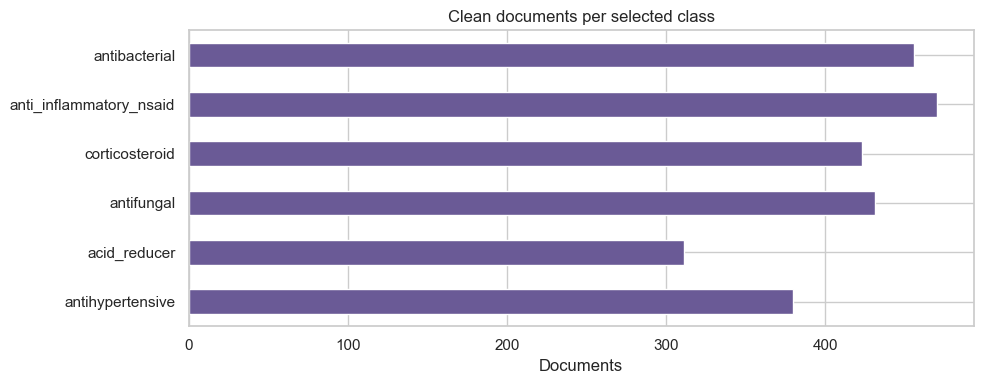

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
balance.documents.plot.barh(ax=ax, color='#6a5a96')
ax.set(title='Clean documents per selected class', xlabel='Documents', ylabel='')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 4. Document lengths

Compact OTC labels and long prescription labels have very different lengths. The saved text is not truncated. Later models will need an explicit truncation or chunking strategy, especially for BERT. Word counts use whitespace splitting and include section headings.

In [6]:
display(df[['word_count', 'character_count', 'section_count']].describe(percentiles=[.1, .25, .5, .75, .9, .95]))
display(df.groupby('class_label').word_count.agg(['min', 'median', 'mean', 'max']).reindex(labels).round(1))

,word_count,character_count,section_count
count,2471.000000,2471.000000,2471.000000
mean,5669.161878,38789.858762,13.233509
std,5267.171879,35795.473213,3.711470
min,91.000000,612.000000,3.000000
10%,355.000000,2069.000000,8.000000
25%,857.500000,5138.500000,10.000000
50%,4467.000000,30650.000000,14.000000
75%,8938.500000,61277.000000,16.000000
90%,14049.000000,94568.000000,18.000000
95%,16405.500000,111682.000000,18.000000


,min,median,mean,max
class_label,,,,
antibacterial,104,5478.0,6638.9,22464
anti_inflammatory_nsaid,182,995.5,5204.8,22945
corticosteroid,112,1834.0,2743.3,18551
antifungal,91,1185.0,5546.5,22456
acid_reducer,293,4662.0,7529.2,17813
antihypertensive,2176,7261.5,6953.7,12018


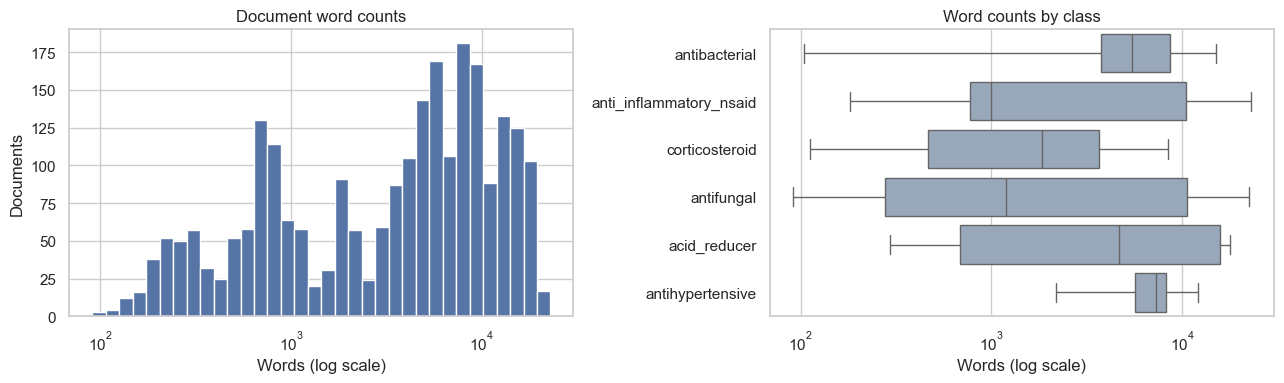

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df.word_count, bins=np.geomspace(df.word_count.min(), df.word_count.max(), 35), color='#5674a5')
axes[0].set_xscale('log')
axes[0].set(title='Document word counts', xlabel='Words (log scale)', ylabel='Documents')
sns.boxplot(data=df, x='word_count', y='class_label', order=labels, showfliers=False, color='#92a6be', ax=axes[1])
axes[1].set_xscale('log')
axes[1].set(title='Word counts by class', xlabel='Words (log scale)', ylabel='')
plt.tight_layout()
plt.show()

## 5. Missing medical sections

Empty fields mean **the corresponding source section was absent**, not that a drug has no risks or side effects. OTC labels can put several facts into one warnings section. No missing medical information is invented. The raw-field missingness table is in `reports/cleaning_summary.json`.

,missing_count,missing_percent
indications_text,2,0.08
dosage_text,8,0.32
warnings_text,7,0.28
contraindications_text,116,4.69
side_effects_text,688,27.84


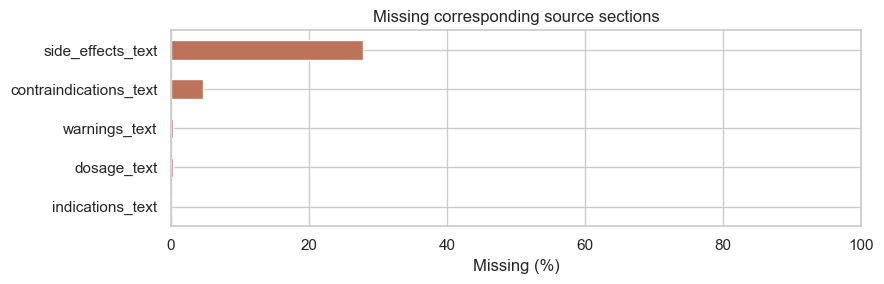

In [8]:
fact_columns = ['indications_text', 'dosage_text', 'warnings_text', 'contraindications_text', 'side_effects_text']
missing = pd.DataFrame({
    'missing_count': df[fact_columns].eq('').sum(),
    'missing_percent': (100 * df[fact_columns].eq('').mean()).round(2),
})
display(missing)
fig, ax = plt.subplots(figsize=(9, 3))
missing.missing_percent.plot.barh(ax=ax, color='#bc735c')
ax.set(title='Missing corresponding source sections', xlabel='Missing (%)', ylabel='', xlim=(0, 100))
plt.tight_layout()
plt.show()

## 6. Most common terms

The reusable EDA script counts lowercase English words of at least three characters across the full corpus, using a small English stop-word list. These tables are an analysis view; they do not alter saved clinical text. Frequent terms can reflect long-label boilerplate as well as class-specific content.

,rank,term,count,document_frequency,document_frequency_percent
0,1,patients,165964,1792,72.52
1,2,use,74131,2471,100.00
2,3,see,69646,1843,74.59
3,4,dose,67779,1944,78.67
4,5,clinical,57655,1789,72.40
5,6,adverse,49793,1789,72.40
6,7,treatment,46283,2022,81.83
7,8,tablets,45221,1212,49.05
8,9,reactions,43922,1888,76.41
9,10,drug,43661,2131,86.24


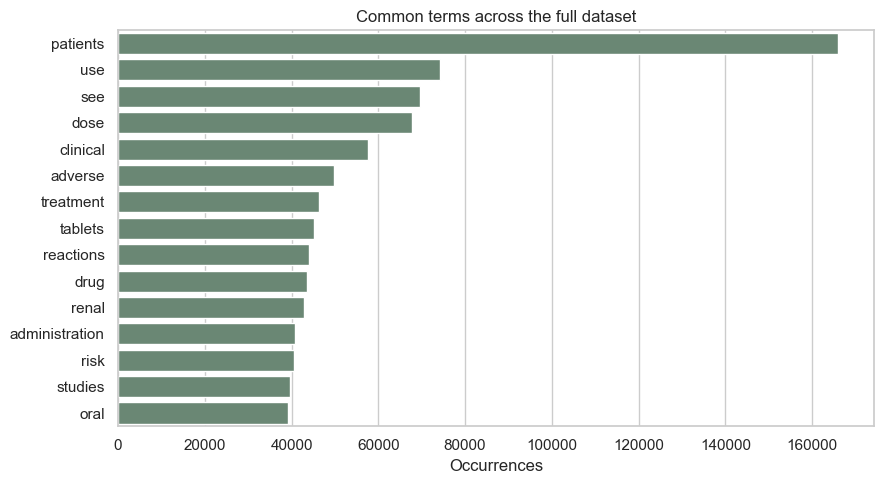

In [9]:
terms = pd.read_csv(REPORTS / 'common_terms.csv')
display(terms.head(15))
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=terms.head(15), x='count', y='term', color='#658c73', ax=ax)
ax.set(title='Common terms across the full dataset', xlabel='Occurrences', ylabel='')
plt.tight_layout()
plt.show()

In [10]:
class_terms = pd.read_csv(REPORTS / 'common_terms_by_class.csv')
display(class_terms.groupby('class_label').head(5).reset_index(drop=True))

,class_label,rank,term,count
0,antibacterial,1,patients,38264
1,antibacterial,2,see,17205
2,antibacterial,3,use,12681
3,antibacterial,4,reactions,12594
4,antibacterial,5,levofloxacin,12302
5,anti_inflammatory_nsaid,1,patients,31666
6,anti_inflammatory_nsaid,2,use,23444
7,anti_inflammatory_nsaid,3,nsaids,21051
8,anti_inflammatory_nsaid,4,renal,15466
9,anti_inflammatory_nsaid,5,see,13443


## 7. Duplicate-aware evaluation preparation

Different manufacturers can supply near-identical labels for the same ingredient. `leakage_group_id` connects shared source UNIIs or ingredient/generic names, including combination-product bridges. Keep these groups disjoint in the later train/validation/test split. Salt synonyms and remaining cross-group near-duplicates still need review.

In [11]:
group_sizes = df.leakage_group_id.value_counts()
print('Duplicate record IDs:', int(df.record_id.duplicated().sum()))
print('Duplicate SPL set IDs:', int(df.set_id.duplicated().sum()))
print('Identical normalized texts:', int(df.document_hash.duplicated().sum()))
print('Independent shared-ingredient groups:', len(group_sizes))
print('Groups containing several documents:', int(group_sizes.gt(1).sum()))
display(pd.read_csv(REPORTS / 'leakage_groups.csv').head(10))

Duplicate record IDs: 0
Duplicate SPL set IDs: 0
Identical normalized texts: 0
Independent shared-ingredient groups: 105
Groups containing several documents: 86


,leakage_group_id,documents,class_labels,example_generic_names
0,group_053492e48466b25a,772,"acid_reducer, anti_inflammatory_nsaid, antibacterial, antifungal, corticosteroid","[""OMEPRAZOLE""]"
1,group_2a96029fb9152979,171,antifungal,"[""CLOTRIMAZOLE""]"
2,group_46d9cd9ae859a7d4,162,antihypertensive,"[""VALSARTAN AND HYDROCHLOROTHIAZIDE""]"
3,group_e73737fb27f505ee,115,acid_reducer,"[""FAMOTIDINE""]"
4,group_a59be682363fef74,72,antibacterial,"[""METRONIDAZOLE""]"
5,group_7aca58014cf8b336,55,antihypertensive,"[""CARVEDILOL""]"
6,group_2e832e4a77c5ad35,54,corticosteroid,"[""PREDNISONE""]"
7,group_51a6080846d97345,53,antifungal,"[""FLUCONAZOLE""]"
8,group_6c9a78f879ba025b,50,acid_reducer,"[""LANSOPRAZOLE""]"
9,group_3f9e0405a5b078ba,49,corticosteroid,"[""TRIAMCINOLONE ACETONIDE""]"


## 8. Inspect a real source example

This is an excerpt of a real retained label. The full text and source link are in the dataset. `data/processed/review_sample.csv` provides two complete documents per class for manual review. Extracted fact-section columns retain the source passage rather than interpreting a patient's dose.

In [12]:
example = df.loc[df.class_label.eq('antibacterial')].sort_values('word_count').iloc[0]
print('Class:', example.class_label)
print('Generic names:', example.generic_names)
print('Source:', example.source_url)
print('Section names:', ', '.join(json.loads(example.sections_json).keys()))
print('Document excerpt (first 1,800 characters):')
print(example.document_text[:1800])

Class: antibacterial
Generic names: ["TRIPLE ANTIBIOTIC"]
Source: https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=5a7cb52d-a60c-b947-e063-6394a90afb0d
Section names: indications_and_usage, purpose, dosage_and_administration, warnings, keep_out_of_reach_of_children
Document excerpt (first 1,800 characters):
Indications And Usage
FIRST AID TO HELP PREVENT INFECTION IN MINOR CUTS, SCRAPES, AND BURNS Indica

Purpose
prevent infection prevent infection

Dosage And Administration
CLEAN THE AFFECTED AREA. APPLY A SMALL AMOUNT OF THIS PRODUCT(AN AMOUNT EQUAL TO THE SURFACE AREA OF THE TIP OF A FINGER) ON THE AREA 1 TO 3 TIMES DAILY. MAY BE COVERED WITH A STERILE BANDAGE. Dosage & Administration

Warnings
WARNING FOR EXTERNAL USE ONLY warning section

Keep Out Of Reach Of Children
KEEP OUT OF REACH OF CHILDREN. IF SWALLOWED, GET MEDICAL HELP OR CONTACT A POISON CONTROL CENTER RIGHT AWAY. keep out of reach of children


## 9. Verification and review checkpoint

Dataset checks verify identifiers, exact target mapping, clinical text counts/hashes, source-section JSON, shared-ingredient grouping, CSV/Parquet equivalence, export checksums, and the exclusion ledger. Software tests additionally exercise dose/negation preservation, ambiguous labels, combination groups, and downloader/cache behavior.

In [13]:
verification = json.loads((REPORTS / 'validation.json').read_text(encoding='utf-8'))
display(pd.DataFrame(verification['checks']))
assert verification['all_passed'], 'Resolve dataset verification failures before review.'
assert verification['record_count'] == len(df)
print('All dataset/export checks passed. Phase 1 is ready for review.')

,name,passed,detail
0,nonempty_dataset,True,"2,471 documents"
1,required_columns,True,Schema present
2,configured_classes_present,True,"acid_reducer, anti_inflammatory_nsaid, antibacterial, antifungal, antihypertensive, corticosteroid"
3,unique_record_id,True,0 duplicate values
4,unique_set_id,True,0 duplicate values
5,unique_document_hash,True,0 duplicate values
6,minimum_document_length,True,Minimum 91 words
7,stored_word_counts,True,Word counts recomputed from exported text
8,stored_character_counts,True,Character counts recomputed from exported text
9,stored_document_hashes,True,SHA-256 of whitespace/case-normalized text


All dataset/export checks passed. Phase 1 is ready for review.


## Stop for Phase 1 review

Review the six categories, source examples, class balance, missing sections, text lengths, and ingredient-group counts in `reports/phase_1_review.md`.

**The next phase begins after your review.** Phase 2 will build and compare TF-IDF Logistic Regression, Linear SVM, and Random Forest baselines using a documented held-out split. English is the initial corpus; Arabic remains a later extension as outlined in the original plan.